In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
file_path = "../data/raw/Online Retail.xlsx"

df = pd.read_excel(file_path)

In [107]:
df.shape
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [109]:
missing = pd.DataFrame({
    "MissingValues": df.isna().sum(),
    "Percentage": df.isna().mean() * 100
})

missing.sort_values("Percentage", ascending=False)

,MissingValues,Percentage
CustomerID,135080,24.926694
Description,1454,0.268311
InvoiceNo,0,0.000000
StockCode,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


In [110]:
missing_description = df[df["Description"].isna()]

print("Number of affected rows:", len(missing_description))
print("Number of distinct StockCodes:",
      missing_description["StockCode"].nunique())

missing_description["StockCode"].value_counts().head(15)

Number of affected rows: 1454
Number of distinct StockCodes: 960


StockCode
35965     10
23084     10
22084      9
22451      6
21784      5
22501      5
22866      5
23348      5
21067      5
21033      5
22139      4
84534B     4
22034      4
22114      4
21429      4
Name: count, dtype: int64

In [111]:
description_reference = (
    df[df["Description"].notna()]
    .groupby("StockCode")["Description"]
    .nunique()
)

missing_codes = missing_description["StockCode"].unique()

reference_check = description_reference.reindex(
    missing_codes,
    fill_value=0
)

reference_check.value_counts().sort_index()

Description
0    112
1    674
2    122
3     35
4     11
5      2
6      2
7      1
8      1
Name: count, dtype: int64

In [112]:
ambiguous_codes = reference_check[reference_check > 1].index

ambiguous_descriptions = (
    df[df["StockCode"].isin(ambiguous_codes)]
    [["StockCode", "Description"]]
    .drop_duplicates()
    .assign(StockCode=lambda x: x["StockCode"].astype(str))
    .sort_values("StockCode")
)

ambiguous_descriptions.head(30)

,StockCode,Description
103332,10080,GROOVY CACTUS INFLATABLE
454350,10080,check
279310,10080,NaN
23437,15058A,BLUE POLKADOT GARDEN PARASOL
192289,15058A,wet/rusty
108588,15058A,NaN
41422,16045,POPART WOODEN PENCILS ASST
341601,16045,NaN
522163,16045,check
270168,16162M,THE KING GIFT BAG 25x24x12cm


In [113]:
invoice_customer_details = (
    df.groupby("InvoiceNo")["CustomerID"]
    .agg(
        TotalRows="size",
        KnownCustomers="nunique",
        MissingCustomers=lambda x: x.isna().sum()
    )
)

# Factures sans aucun CustomerID connu
unknown_invoices = invoice_customer_details[
    invoice_customer_details["KnownCustomers"] == 0
]

print("Nombre de factures sans CustomerID connu :",
      len(unknown_invoices))

print("Nombre de lignes concernées :",
      unknown_invoices["TotalRows"].sum())

Nombre de factures sans CustomerID connu : 3710
Nombre de lignes concernées : 135080


In [114]:
df_clean = df.copy()

# Autoriser les identifiants numériques et textuels
df_clean["CustomerID"] = df_clean["CustomerID"].astype("object")

# Identifier les factures sans aucun CustomerID connu
unknown_invoice_numbers = unknown_invoices.index

mask = (
    df_clean["InvoiceNo"].isin(unknown_invoice_numbers)
    & df_clean["CustomerID"].isna()
)

# Attribuer un identifiant fictif unique par facture
df_clean.loc[mask, "CustomerID"] = (
    "UNKNOWN_" + df_clean.loc[mask, "InvoiceNo"].astype(str)
)

In [115]:
print("CustomerID manquants :", df_clean["CustomerID"].isna().sum())

print(
    "Identifiants fictifs :",
    df_clean["CustomerID"].astype(str).str.startswith("UNKNOWN_").sum()
)

CustomerID manquants : 0
Identifiants fictifs : 135080


In [116]:
customer_per_invoice = (
    df_clean.groupby("InvoiceNo")["CustomerID"]
    .nunique()
)

customer_per_invoice.value_counts().sort_index()


df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   541909 non-null  object        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(4), str(1)
memory usage: 33.1+ MB


In [117]:
negative_quantity = df[df["Quantity"] < 0]

print("Nombre de lignes avec quantité négative :", len(negative_quantity))
print("Pourcentage :", round(len(negative_quantity) / len(df) * 100, 2), "%")

print("\nRépartition des quantités :")
print(df["Quantity"].describe())

Nombre de lignes avec quantité négative : 10624
Pourcentage : 1.96 %

Répartition des quantités :
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64


In [118]:
zero_price = df_clean[df_clean["UnitPrice"] == 0]

print("Nombre de lignes avec prix nul :", len(zero_price))
print("Pourcentage :", round(len(zero_price) / len(df_clean) * 100, 2), "%")

Nombre de lignes avec prix nul : 2515
Pourcentage : 0.46 %


In [119]:
zero_price["StockCode"].value_counts().head(20)

StockCode
23084     16
35965     13
20713     11
22501     10
22676      9
22627      9
22084      9
22683      8
21116      8
46000S     8
82583      8
22734      7
22679      7
22686      7
22625      7
79321      7
22678      7
22666      7
23348      7
21830      7
Name: count, dtype: int64

In [120]:
df_clean[df_clean["StockCode"]==21830]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2599,536592,21830,ASSORTED CREEPY CRAWLIES,1,2010-12-01 17:06:00,0.85,UNKNOWN_536592,United Kingdom
4040,536743,21830,ASSORTED CREEPY CRAWLIES,48,2010-12-02 13:32:00,0.42,17964.0,United Kingdom
6449,536945,21830,ASSORTED CREEPY CRAWLIES,24,2010-12-03 12:24:00,0.42,14083.0,United Kingdom
6473,536945,21830,ASSORTED CREEPY CRAWLIES,24,2010-12-03 12:24:00,0.42,14083.0,United Kingdom
8431,537135,21830,ASSORTED CREEPY CRAWLIES,1,2010-12-05 12:35:00,0.42,17059.0,United Kingdom
...,...,...,...,...,...,...,...,...
401462,571441,21830,ASSORTED CREEPY CRAWLIES,1,2011-10-17 13:31:00,0.83,14096.0,United Kingdom
416159,572552,21830,ASSORTED CREEPY CRAWLIES,1,2011-10-24 17:07:00,0.83,14096.0,United Kingdom
429663,573576,21830,ASSORTED CREEPY CRAWLIES,2,2011-10-31 14:09:00,0.83,14096.0,United Kingdom
468999,576566,21830,NaN,-186,2011-11-15 13:39:00,0.00,UNKNOWN_576566,United Kingdom


In [121]:
price_counts = (
    df_clean.groupby("StockCode")
    .agg(
        TotalObservations=("UnitPrice", "size"),
        ZeroPrices=("UnitPrice", lambda x: (x == 0).sum()),
        PositivePrices=("UnitPrice", lambda x: (x > 0).sum())
    )
)

price_counts[
    (price_counts["ZeroPrices"] > 0) &
    (price_counts["PositivePrices"] > 1)
].sort_values("ZeroPrices", ascending=False).head(10)

,TotalObservations,ZeroPrices,PositivePrices
StockCode,,,
23084,1067,16,1051
35965,83,13,70
20713,684,11,673
22501,474,10,464
22676,213,9,204
22627,382,9,373
22084,457,9,448
46000S,196,8,188
21116,260,8,252


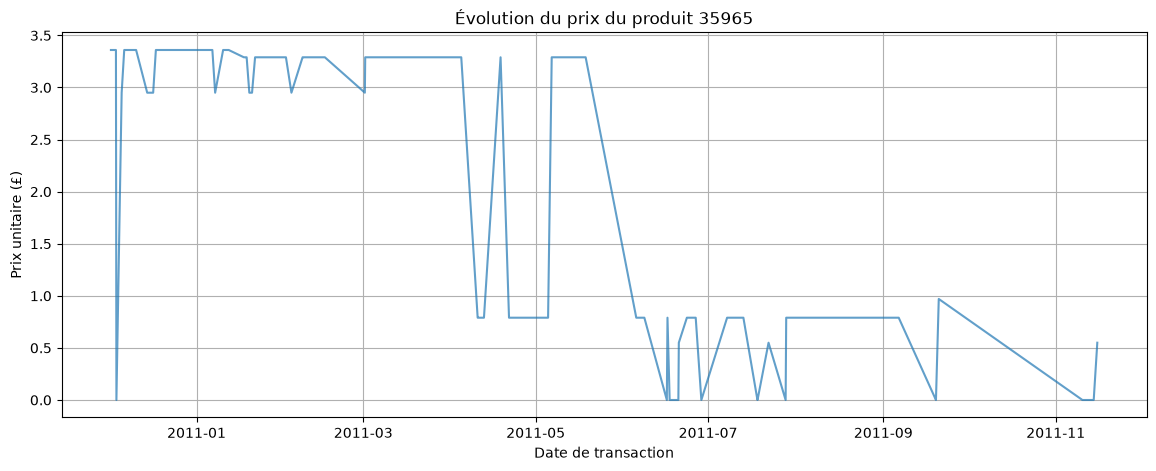

In [122]:
product_data = (
    df_clean[df_clean["StockCode"] == 35965]
    .sort_values("InvoiceDate")
)

plt.figure(figsize=(14, 5))

plt.plot(
    product_data["InvoiceDate"],
    product_data["UnitPrice"],
    alpha=0.7
)

plt.title("Évolution du prix du produit 35965")
plt.xlabel("Date de transaction")
plt.ylabel("Prix unitaire (£)")
plt.grid(True)
plt.show()

In [123]:
df_price_clean = df_clean.copy()

print("Dimensions :", df_price_clean.shape)
print("Prix nuls :", (df_price_clean["UnitPrice"] == 0).sum())
print("Produits concernés :", df_price_clean.loc[
    df_price_clean["UnitPrice"] == 0, "StockCode"
].nunique())

Dimensions : (541909, 8)
Prix nuls : 2515
Produits concernés : 1419
